> ✏️ **실습본(코드-along)** — 설명을 읽고 `# 👉` 부분을 직접 채워 실행하세요. 막히면 완성본을 참고하세요.

# 데이터 구조 변환 — `melt` · `pivot` · `pivot_table`
### 같은 데이터, 모양만 바꾸기

데이터의 **값은 그대로 두고 '모양(형태)'만 바꾸는** 방법을 배웁니다.
왜 필요할까요? — 같은 데이터라도 **사람이 읽기 좋은 모양**과 **집계·그래프에 좋은 모양**이 다르기 때문입니다.

- `melt` : 옆으로 퍼진 표(Wide)를 아래로 길게(Long)
- `pivot` : 다시 옆으로(Long → Wide) 되돌리기
- `pivot_table` : 되돌리면서 **집계까지**(합계·평균 등)

> **진행 방식** — 앞부분은 **작은 예제로 개념**을 익히고, 뒷부분(**▶ 실전**)은 Day1에서 만든 통합 주문 데이터로 요약표를 만들고 "값이 그대로인지"까지 검증합니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns          # 여러 계열을 색으로 구분해 겹쳐 그릴 때 사용

# ---------------------------------------
# 한글 폰트 설정 (OS 자동 감지) — 그래프에서 한글이 깨지지 않게
# ---------------------------------------
import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')     # 윈도우
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')        # 맥
else:
    plt.rc('font', family='NanumGothic')        # 리눅스 / 구글 코랩
plt.rc('axes', unicode_minus=False)             # 마이너스(-) 부호 깨짐 방지

---
## 1. Wide vs Long — 두 가지 표 모양

먼저 용어부터. 같은 데이터를 담는 두 가지 모양입니다.

- **Wide(넓은 형태)** : 한 항목이 여러 열로 옆으로 펼쳐짐 (예: `2025-01`·`2025-02`·`2025-03`이 각각 열). 사람 눈에 보기 편함.
- **Long(긴 형태)** : `변수=열, 값=행` 으로 아래로 쌓임. 집계·시각화에 편함.

목적에 따라 이 둘을 오갑니다. 아래 예시부터 봅시다.

In [2]:
# Wide 형태 예시: 한 행 = 한 지역, 각 '월'이 옆으로(열) 펼쳐져 있음
sales_wide = pd.DataFrame({'region':['서울','부산'], '2025-01':[1200,800], '2025-02':[1350,830], '2025-03':[1280,910]})
sales_wide   # 눈엔 편하지만, 월이 3개 열로 흩어져 있어 집계·그래프엔 불편

,region,2025-01,2025-02,2025-03
0,서울,1200,1350,1280
1,부산,800,830,910


---
## 2. `melt` — Wide → Long (옆으로 퍼진 값을 아래로 모으기)

여러 열에 흩어진 값을 **'이름 열' 하나 + '값 열' 하나**로 모읍니다.

In [ ]:
# melt = 여러 '월' 열에 흩어진 값을 아래(행)로 모으기 (Wide → Long)
#   id_vars    : 그대로 둘 기준 열 (region은 식별자라 값으로 내리지 않음)
#   var_name   : 열 이름들이 담길 새 컬럼명  → 'month'
#   value_name : 실제 값이 담길 새 컬럼명    → 'sales'
# 👉 여기에 코드를 작성하세요

| 옵션 | 의미 |
|---|---|
| `id_vars` | 그대로 둘 식별 컬럼(기준) |
| `value_vars` | 행으로 내릴 컬럼(생략하면 나머지 전부) |
| `var_name` / `value_name` | 새로 생기는 '이름'열 / '값'열의 이름 |

> ⚠️ **식별 컬럼(`id_vars`)을 빠뜨리면** `region`까지 값으로 내려가 버립니다. "그대로 둘 열"은 꼭 `id_vars`에 적어주세요.

### Long이 왜 좋을까? — 그래프 한 줄로 끝

Long 형태면 seaborn에서 `hue='과목'` **한 줄**로 여러 계열(과목)을 색으로 나눠 겹쳐 그릴 수 있습니다.
Wide였다면 과목마다 따로 그려야 했겠죠.

<Axes: xlabel='이름', ylabel='점수'>

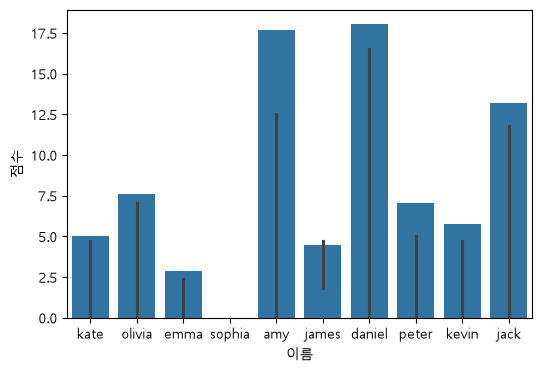

In [17]:
# scores.csv: 학생별 국어·영어·수학 점수가 '열'로 흩어진 Wide 데이터
df = pd.read_csv('data/scores.csv')
df

# 과목 3개 열(국어·영어·수학)을 '과목'·'점수' 두 열로 모음 → Long
# 👉 여기에 코드를 작성하세요
df_melt = df.melt(id_vars=['학번','이름','성별'],
        value_vars=['국어','영어','수학'],
        var_name='과목',
        value_name='점수')

# Long이면 hue='과목' 한 줄로 학생별 과목 막대를 색으로 나눠 그릴 수 있음
# 👉 여기에 코드를 작성하세요
plt.figure(figsize=(6,4))
sns.barplot(data=df_melt, x='이름', y='점수', estimator='std')

<Axes: xlabel='이름', ylabel='점수'>

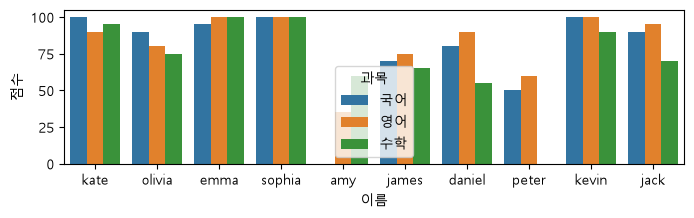

In [13]:
plt.figure(figsize=(8,2))
sns.barplot(data=df_melt, x='이름', y='점수', hue='과목')

> 💡 melt로 열 이름에서 내려온 `month`·`과목`은 **문자열(text)** 입니다.
> 날짜로 다뤄야 하면 `pd.to_datetime(..., format='%Y-%m')`으로 변환하세요.

---
## 3. `pivot` — Long → Wide (다시 옆으로 되돌리기)

`melt`의 **정확한 반대**입니다. 단, 되돌리려면 **(행, 열) 조합이 겹치지 않고 고유해야** 합니다.

In [21]:
# pivot = melt의 반대. Long → Wide 로 되돌림
#   index   : 행이 될 열   → region
#   columns : 열이 될 열   → month (이 열의 값들이 새 '열 이름'이 됨)
#   values  : 표를 채울 값 → sales
# 👉 여기에 코드를 작성하세요
df_pivot = df_melt.pivot(index=['학번','이름','성별'],
              columns=['과목'],
              values=['점수']).reset_index()
df_pivot.columns = ['학번','이름','성별','국어','수학','영어']
df_pivot

,학번,이름,성별,국어,수학,영어
0,1,kate,f,100.0,95.0,90.0
1,2,olivia,f,90.0,75.0,80.0
2,3,emma,f,95.0,100.0,100.0
3,4,sophia,f,100.0,100.0,100.0
4,5,amy,f,NaN,60.0,35.0
5,6,james,m,70.0,65.0,75.0
6,7,daniel,m,80.0,55.0,90.0
7,8,peter,m,50.0,NaN,60.0
8,9,kevin,m,100.0,90.0,100.0
9,10,jack,m,90.0,70.0,95.0


### ⚠️ 조합이 중복이면 오류가 납니다

같은 `(지역, 월)`이 여러 행이면, `pivot`은 그 칸에 **어떤 값을 넣을지 정할 수 없어** 오류를 냅니다.

In [22]:
# (지역, 월) 조합이 중복인 데이터를 일부러 만들어 봄
sales_dup = pd.DataFrame({'region':['서울','서울','서울'], 'month':['2025-01','2025-01','2025-02'], 'sales':[700,500,1350]})
try:
    sales_dup.pivot(index='region', columns='month', values='sales')
except Exception as e:
    print('오류:', type(e).__name__, '→ 같은 (서울, 2025-01)이 2행이라 값을 하나로 못 정함')

오류: ValueError → 같은 (서울, 2025-01)이 2행이라 값을 하나로 못 정함


이럴 땐 행을 **지우는 게 아니라 합치거나 평균내야** 합니다 → 그래서 `pivot_table`이 필요합니다.

---
## 4. `pivot_table` — 집계하면서 Wide로

중복 조합을 **집계(합계·평균 등)로 처리**하면서 Wide 표를 만듭니다. `pivot`이 실패하던 상황을 해결합니다.

In [24]:
# pivot_table = 중복 조합을 '집계'하면서 Wide로 (pivot이 실패하던 상황을 해결)
#   aggfunc='sum' : 같은 칸에 여러 값이 모이면 합산
# 👉 여기에 코드를 작성하세요
# (서울, 2025-01)의 700 + 500 = 1200 으로 합쳐짐

df_pivot_table = df_melt.pivot_table(index=['학번','이름','성별'],
                                     columns=['과목'],
                                     values=['점수'],
                                     aggfunc= 'mean',
                                     margins=True).round(2)
df_pivot_table

점수                       
과목                국어     수학      영어     All
학번  이름     성별                              
1   kate   f   100.0   95.0   90.00   95.00
2   olivia f    90.0   75.0   80.00   81.67
3   emma   f    95.0  100.0  100.00   98.33
4   sophia f   100.0  100.0  100.00  100.00
5   amy    f     NaN   60.0   35.00   47.50
6   james  m    70.0   65.0   75.00   70.00
7   daniel m    80.0   55.0   90.00   75.00
8   peter  m    50.0    NaN   60.00   55.00
9   kevin  m   100.0   90.0  100.00   96.67
10  jack   m    90.0   70.0   95.00   85.00
11  james  m    70.0   65.0   75.00   70.00
All             84.5   77.5   81.82   81.29

### 꼭 기억할 함정 — 기본 집계는 '평균'

`aggfunc`를 지정하지 않으면 기본은 **평균**입니다. 합계가 필요하면 `aggfunc='sum'`을 반드시 지정하세요. (안 그러면 조용히 평균이 나옵니다.)

In [ ]:
# ⚠️ aggfunc를 안 적으면 기본은 '평균'! 합계가 필요하면 sum 을 꼭 지정
# 👉 여기에 코드를 작성하세요

### `groupby` vs `pivot_table` — 뭘 쓸까?

둘은 **숫자(값)가 똑같습니다.** 아무거나 써도 결과 값은 같아요 — 차이는 결과의 **모양**뿐입니다.

- **`groupby(...).sum()`** → 세로로 **길게(Long)**. 집계한 뒤 **이어서 계산·필터·정렬**할 때 편함.
- **`pivot_table(...)`** → 행 × 열 **표(Wide, 교차표)**. **사람이 보기 좋은 요약표**·히트맵일 때 편함.

> 한마디로 **`pivot_table` = `groupby` 결과를 표로 편 것.**
> 두 기준을 **교차표(행×열)로 보고 싶으면 `pivot_table`**, 집계 후 **이어서 코드로 더 다룰 거면 `groupby`**.

아래에서 **같은 숫자가 두 모양으로** 나오는 걸 확인하세요.

In [ ]:
# pivot_table 은 groupby 결과를 표로 펼친 것 — 숫자는 같고 모양만 다름
# 👉 여기에 코드를 작성하세요

---
# ▶ 실전 — 요약표 만들고 "값 보존" 검증

개념을 익혔으니, Day1에서 만든 **통합 주문 데이터**와 지역별 월매출표(`sales_wide`)로 실전 요약표를 만듭니다.
핵심 질문은 하나 — **모양은 바꿨지만, 값은 그대로인가?**

In [ ]:
# ─────────────────────────────────────────────────────────────
# [제공 셀] 읽지 말고 그대로 실행하세요.
#   Day1 앞부분(1_결합)에서 만든 '통합 주문 데이터(df)'를 다시 만드는 코드입니다.
#   결과: df = 주문상품 한 줄마다 주문·상품·고객 정보가 모두 붙은 큰 표
# ─────────────────────────────────────────────────────────────
# 👉 여기에 코드를 작성하세요

## 실전 1. `melt`로 Wide → Long 펴기

`sales_wide`(지역 5 × 월 12)를 Long으로 폅니다. 월 12개 열이 세로로 쌓여 **60행**이 되는지 확인해봅니다.

In [ ]:
# 변환 전 — Wide 모양 (지역이 행, 월이 옆으로 12개 열로 펼쳐짐)
sales_wide.head()

In [ ]:
# melt 로 Long 으로 변환
# 👉 여기에 코드를 작성하세요

# 변환 후 — Long 모양 (region · month · sales 3개 열로 세로로 쌓임)
# 👉 여기에 코드를 작성하세요

In [ ]:
# 행 수만 가볍게 확인: 지역 5 × 월 12 = 60행이어야 정상
# (melt는 값을 재배치만 하므로 총합은 자동으로 보존됩니다 — 합계 대조는 집계·결합 때 하면 됩니다)
print('행수:', len(sales_long), '→ 5×12=60 이어야 정상:', len(sales_long)==60)

## 실전 2. `pivot`으로 되돌리기

방금 편 것을 다시 Wide로 되돌려, `melt`↔`pivot`이 서로 반대임을 확인합니다.

In [ ]:
# melt로 편 것을 pivot으로 되돌리면 원래 Wide와 같은 모양 → 둘은 서로 반대
# 👉 여기에 코드를 작성하세요

> 📌 **이 표 읽는 법** (처음엔 헷갈리는 부분)
> - 왼쪽 `0,1,2,3,4` = `reset_index()`가 새로 붙인 **행 번호**(인덱스)
> - `region` · `2025-01` … 은 **모두 진짜 열** — 그중 `region`은 `reset_index()`로 인덱스에서 열로 내려온 것
> - `pivot(columns='month')` 흔적으로 표 **왼쪽 위**에 붙던 `month`는 열이 아니라 **"열들의 이름표"(열축 이름)** 였습니다. 위에서 `back.columns.name = None`으로 지웠어요.

## 실전 3. `pivot_table`로 요약표 만들기

통합 데이터로 **카테고리(행) × 월(열) 매출 합계**표를 만듭니다. (`aggfunc='sum'` 잊지 않기)

In [ ]:
# 통합 데이터로 요약표: 카테고리(행) × 월(열) 매출 '합계'
#   aggfunc='sum' : 매출은 합계로
#   fill_value=0  : 값 없는 칸은 0으로 (NaN 대신 보기 좋게)
# 👉 여기에 코드를 작성하세요

## 실전 4. 개수는 `nunique`로 세기

이제 '주문 수'를 세는 표를 만들 차례입니다. 그런데 `df`는 **한 줄 = "한 주문에 담긴 상품 하나"** 라, 상품 3개를 담은 주문은 **3줄**로 들어가 있어요.
그래서 `aggfunc='count'`로 세면 그 주문이 3번 세어져 **부풀려집니다.** 서로 다른 주문 수는 `aggfunc='nunique'` — 아래에서 두 결과를 비교해보세요.

In [ ]:
# ⚠️ '주문 수'를 셀 땐 count가 아니라 nunique!
#    df는 '주문상품' 한 줄 단위라, 한 주문에 상품이 여러 개면 count는 중복으로 부풀려짐
# 👉 여기에 코드를 작성하세요

# 비교: count 는 주문상품 줄 수라 실제 주문 수보다 큼
# 👉 여기에 코드를 작성하세요

## 실전 5. 요약표에서 인사이트 읽기

카테고리별 연매출 순위와 월별 매출 추세를 봅니다.

In [ ]:
# 카테고리별 연매출 순위 (월별 합을 다시 가로로 합산)
# 👉 여기에 코드를 작성하세요

# 월별 총매출 추세선
# 👉 여기에 코드를 작성하세요

---
## ✅ 정리 — 핵심 3가지

1. **`melt`(Wide→Long)** 와 **`pivot`(Long→Wide)** 은 서로 반대. `pivot`은 (행, 열) 조합이 고유해야 함.
2. **`pivot_table`** 은 집계하며 Wide로 — **기본이 평균**이니 합계는 `aggfunc='sum'`, 주문 수는 `nunique`.
3. 구조 변환은 **값이 아니라 모양**을 바꾸는 일. 늘 마지막에 묻는다 — *모양은 바뀌었지만 값은 그대로인가?*